# Progress 1 — Pengumpulan dan Eksplorasi Data Harga Pangan Jawa Timur 2025

**Judul proyek:** *Perbandingan ARIMA dan Exponential Smoothing untuk Analisis Harga Pangan di Jawa Timur Tahun 2025.*

**24083010095 - Selvy Dwi Yulita Sari**

## Tujuan Progress 1
1. Memeriksa dua dataset: Neraca Bahan Makanan (NBM) Jawa Timur 2025 dan harga pangan bulanan Januari–Desember 2025.
2. Memeriksa struktur, kelengkapan, dan karakteristik data.
3. Memvisualisasikan perubahan harga pangan bulanan.
4. Mengidentifikasi **indikasi visual** ketidakstasioneran sebagai eksplorasi awal.

**Batasan:** Progress 1 belum melakukan pemodelan ARIMA atau Exponential Smoothing, belum memilih parameter model, dan belum membandingkan performa model. Data NBM tahunan dan data harga bulanan memiliki struktur berbeda sehingga tidak digabungkan secara langsung.
```[cite: 1]

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 30)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [32]:
import os

print("File dalam folder:")
print(os.listdir())

File dalam folder:
['Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi.csv', 'Neraca Bahan Makanan_NBM 2025.xlsx', 'progress_1.ipynb']


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Nama file sesuai folder VS Code
harga_file = "Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi.csv"
nbm_file = "Neraca Bahan Makanan_NBM 2025.xlsx"

# Membaca dataset harga pangan
harga = pd.read_csv(harga_file)

# Membaca dataset NBM
nbm = pd.ExcelFile(nbm_file)

print("Kedua dataset berhasil dibaca!")

print("\nSheet pada dataset NBM:")
print(nbm.sheet_names)

print("\nLima data pertama harga pangan:")
display(harga.head())

Kedua dataset berhasil dibaca!

Sheet pada dataset NBM:
['Tabel NBM', 'PPH NBM']

Lima data pertama harga pangan:


,Kode Provinsi,Nama Provinsi,Tahun,Urutan Bulan,Bulan,Komoditas,Harga,Harga (Rp),Status Data,Metode Estimasi,Sumber Acuan
0,35,Jawa Timur,2025,1,Januari,Bawang Merah,"Rp34,046",34046.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
1,35,Jawa Timur,2025,2,Februari,Bawang Merah,"Rp29,260",29260.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
2,35,Jawa Timur,2025,3,Maret,Bawang Merah,"Rp41,017",41017.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
3,35,Jawa Timur,2025,4,April,Bawang Merah,"Rp43,186",43186.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
4,35,Jawa Timur,2025,5,Mei,Bawang Merah,"Rp35,940",35940.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...


In [34]:
# Membaca seluruh sheet NBM
nbm_sheets = {}

for sheet in nbm.sheet_names:
    nbm_sheets[sheet] = pd.read_excel(nbm_file, sheet_name=sheet)

    print("\nNama Sheet:", sheet)
    print("Ukuran Data:", nbm_sheets[sheet].shape)

    display(nbm_sheets[sheet].head())


Nama Sheet: Tabel NBM
Ukuran Data: (187, 40)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Ketersediaan Per Kapita,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Nbm123
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kalori,Protein,Lemak,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NERACA BAHAN MAKANAN / FOOD BALANCE SHEET,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Total :,NaN,3442.028566,111.269645,57.94108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,PROV JAWA TIMUR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Nabati :,NaN,3134.937047,84.623029,37.391874,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TAHUN 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Hewani :,NaN,307.091519,26.646616,20.549206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Nama Sheet: PPH NBM
Ukuran Data: (57, 15)


,ZONASI I,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,"KETERSEDIAAN ENERGI, PROTEIN, DAN LEMAK",Unnamed: 12,Unnamed: 13,Unnamed: 14
0,Pola Pangan Harapan (PPH) Tingkat Ketersediaan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PER KELOMPOK PANGAN,NaN,NaN,NaN
1,Berdasarkan Neraca Bahan Makanan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TAHUN 2025,NaN,NaN,NaN
2,TAHUN 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Kelompok Bahan Pangan,Energi,Protein,Lemak
3,No.,Kelompok,Energi,% AKE,Bobot,Skor riil,Skor PPH,Skor Maks,Ket,NaN,NaN,NaN,(kkal/kap/hari),(gram/kap/hari),(gram/kap/hari)
4,NaN,Bahan Pangan,(Kalori),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(1),(2),(3),(4)


In [35]:
print("Lima data pertama:")
display(harga.head())

print("\nInformasi dataset:")
harga.info()

print("\nNama seluruh kolom:")
print(harga.columns.tolist())

Lima data pertama:


,Kode Provinsi,Nama Provinsi,Tahun,Urutan Bulan,Bulan,Komoditas,Harga,Harga (Rp),Status Data,Metode Estimasi,Sumber Acuan
0,35,Jawa Timur,2025,1,Januari,Bawang Merah,"Rp34,046",34046.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
1,35,Jawa Timur,2025,2,Februari,Bawang Merah,"Rp29,260",29260.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
2,35,Jawa Timur,2025,3,Maret,Bawang Merah,"Rp41,017",41017.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
3,35,Jawa Timur,2025,4,April,Bawang Merah,"Rp43,186",43186.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
4,35,Jawa Timur,2025,5,Mei,Bawang Merah,"Rp35,940",35940.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Kode Provinsi    300 non-null    int64  
 1   Nama Provinsi    300 non-null    object 
 2   Tahun            300 non-null    int64  
 3   Urutan Bulan     300 non-null    int64  
 4   Bulan            300 non-null    object 
 5   Komoditas        300 non-null    object 
 6   Harga            288 non-null    object 
 7   Harga (Rp)       284 non-null    float64
 8   Status Data      300 non-null    object 
 9   Metode Estimasi  25 non-null     object 
 10  Sumber Acuan     296 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 25.9+ KB

Nama seluruh kolom:
['Kode Provinsi', 'Nama Provinsi', 'Tahun', 'Urutan Bulan', 'Bulan', 'Komoditas', 'Harga', 'Harga (Rp)', 'Status Data', 'Metode Estimasi', 'Sumber Acuan']


In [36]:
# Memeriksa nilai kosong
print("Jumlah nilai kosong:")
display(harga.isnull().sum())

# Memeriksa data duplikat
print("\nJumlah data duplikat:")
print(harga.duplicated().sum())

# Statistik deskriptif
print("\nStatistik deskriptif:")
display(harga.describe(include="all").T)

Jumlah nilai kosong:


Kode Provinsi        0
Nama Provinsi        0
Tahun                0
Urutan Bulan         0
Bulan                0
Komoditas            0
Harga               12
Harga (Rp)          16
Status Data          0
Metode Estimasi    275
Sumber Acuan         4
dtype: int64


Jumlah data duplikat:
0

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Kode Provinsi,300.0,NaN,NaN,NaN,35.0,0.0,35.0,35.0,35.0,35.0,35.0
Nama Provinsi,300,1,Jawa Timur,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tahun,300.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
Urutan Bulan,300.0,NaN,NaN,NaN,6.5,3.45782,1.0,3.75,6.5,9.25,12.0
Bulan,300,12,Januari,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Komoditas,300,25,Bawang Merah,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Harga,288,263,"Rp120,000",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Harga (Rp),284.0,NaN,NaN,NaN,30878.897887,28792.467105,5283.0,12110.75,20060.0,34715.0,123286.0
Status Data,300,3,AKTUAL - SESUAI FILE SUMBER,271,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metode Estimasi,25,2,Estimasi sementara: memakai harga November 202...,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
def cari_kolom(kolom, kata_kunci):
    for nama in kolom:
        nama_bersih = str(nama).lower().strip()

        if any(kata in nama_bersih for kata in kata_kunci):
            return nama

    return None


kolom_tanggal = cari_kolom(
    harga.columns,
    ["tanggal", "bulan", "periode", "date", "month", "waktu"]
)

kolom_komoditas = cari_kolom(
    harga.columns,
    ["komoditas", "komoditi", "commodity", "pangan"]
)

kolom_harga = cari_kolom(
    harga.columns,
    ["harga", "price"]
)

kolom_status = cari_kolom(
    harga.columns,
    ["status", "keterangan", "jenis_data", "estimasi"]
)

print("Kolom tanggal:", kolom_tanggal)
print("Kolom komoditas:", kolom_komoditas)
print("Kolom harga:", kolom_harga)
print("Kolom status:", kolom_status)

Kolom tanggal: Urutan Bulan
Kolom komoditas: Komoditas
Kolom harga: Harga
Kolom status: Status Data


In [38]:
# Gunakan hasil identifikasi Cell 7
KOLOM_TANGGAL = kolom_tanggal
KOLOM_KOMODITAS = kolom_komoditas
KOLOM_HARGA = kolom_harga
KOLOM_STATUS = kolom_status

# Memastikan kolom ditemukan
if any(x is None for x in [
    KOLOM_TANGGAL,
    KOLOM_KOMODITAS,
    KOLOM_HARGA
]):
    raise ValueError(
        "Kolom belum teridentifikasi. "
        "Periksa nama kolom pada Cell 5 dan atur secara manual."
    )

print("Kolom berhasil ditentukan.")

Kolom berhasil ditentukan.


In [39]:
data_harga = harga.copy()

# Mengubah harga menjadi numerik
if not pd.api.types.is_numeric_dtype(data_harga[KOLOM_HARGA]):

    harga_bersih = (
        data_harga[KOLOM_HARGA]
        .astype(str)
        .str.replace("Rp", "", regex=False)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
        .str.replace(r"[^0-9.\-]", "", regex=True)
    )

    data_harga["harga_numerik"] = pd.to_numeric(
        harga_bersih,
        errors="coerce"
    )

else:
    data_harga["harga_numerik"] = pd.to_numeric(
        data_harga[KOLOM_HARGA],
        errors="coerce"
    )

print("Preprocessing harga selesai.")
display(data_harga.head())

Preprocessing harga selesai.


,Kode Provinsi,Nama Provinsi,Tahun,Urutan Bulan,Bulan,Komoditas,Harga,Harga (Rp),Status Data,Metode Estimasi,Sumber Acuan,harga_numerik
0,35,Jawa Timur,2025,1,Januari,Bawang Merah,"Rp34,046",34046.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,34.046
1,35,Jawa Timur,2025,2,Februari,Bawang Merah,"Rp29,260",29260.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,29.260
2,35,Jawa Timur,2025,3,Maret,Bawang Merah,"Rp41,017",41017.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,41.017
3,35,Jawa Timur,2025,4,April,Bawang Merah,"Rp43,186",43186.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,43.186
4,35,Jawa Timur,2025,5,Mei,Bawang Merah,"Rp35,940",35940.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...,35.940


In [40]:
# Konversi tanggal secara umum
data_harga["tanggal"] = pd.to_datetime(
    data_harga[KOLOM_TANGGAL],
    errors="coerce",
    dayfirst=True
)

# Pemetaan nama bulan Indonesia
nama_bulan = {
    "januari": 1,
    "februari": 2,
    "maret": 3,
    "april": 4,
    "mei": 5,
    "juni": 6,
    "juli": 7,
    "agustus": 8,
    "september": 9,
    "oktober": 10,
    "november": 11,
    "desember": 12
}

# Jika format tanggal berupa nama bulan, konversi ke tanggal tahun 2025
bulan_angka = (
    data_harga[KOLOM_TANGGAL]
    .astype(str)
    .str.lower()
    .str.strip()
    .map(nama_bulan)
)

tanggal_bulan = pd.to_datetime(
    {
        "year": 2025,
        "month": bulan_angka,
        "day": 1
    },
    errors="coerce"
)

data_harga["tanggal"] = data_harga["tanggal"].fillna(
    tanggal_bulan
)

print("Contoh hasil konversi tanggal:")
display(data_harga[[KOLOM_TANGGAL, "tanggal"]].head(15))

print(
    "\nJumlah tanggal yang belum terbaca:",
    data_harga["tanggal"].isna().sum()
)

Contoh hasil konversi tanggal:


,Urutan Bulan,tanggal
0,1,1970-01-01 00:00:00.000000001
1,2,1970-01-01 00:00:00.000000002
2,3,1970-01-01 00:00:00.000000003
3,4,1970-01-01 00:00:00.000000004
4,5,1970-01-01 00:00:00.000000005
5,6,1970-01-01 00:00:00.000000006
6,7,1970-01-01 00:00:00.000000007
7,8,1970-01-01 00:00:00.000000008
8,9,1970-01-01 00:00:00.000000009
9,10,1970-01-01 00:00:00.000000010



Jumlah tanggal yang belum terbaca: 0


In [41]:
if KOLOM_STATUS is not None:

    print("Distribusi status data:")
    display(
        data_harga[KOLOM_STATUS]
        .value_counts(dropna=False)
        .to_frame("Jumlah")
    )

    # Memisahkan nilai yang ditandai sebagai estimasi
    data_harga["status_estimasi"] = (
        data_harga[KOLOM_STATUS]
        .astype(str)
        .str.contains(
            "estimasi|estimate|perkiraan|proxy",
            case=False,
            regex=True
        )
    )

    data_aktual = data_harga[
        ~data_harga["status_estimasi"]
    ].copy()

    print("Jumlah seluruh data:", len(data_harga))
    print("Jumlah data aktual:", len(data_aktual))
    print(
        "Jumlah data estimasi:",
        data_harga["status_estimasi"].sum()
    )

else:

    print(
        "Kolom status tidak terdeteksi. "
        "Periksa dokumentasi dataset untuk membedakan "
        "data aktual dan estimasi."
    )

    data_aktual = data_harga.copy()

Distribusi status data:


,Jumlah
Status Data,
AKTUAL - SESUAI FILE SUMBER,271
ESTIMASI - BUKAN DATA AKTUAL BULANAN,25
TIDAK TERSEDIA DALAM FILE SUMBER,4


Jumlah seluruh data: 300
Jumlah data aktual: 275
Jumlah data estimasi: 25


In [42]:
daftar_komoditas = sorted(
    data_harga[KOLOM_KOMODITAS]
    .dropna()
    .astype(str)
    .unique()
)

print("Jumlah komoditas:", len(daftar_komoditas))

for nomor, komoditas in enumerate(daftar_komoditas, start=1):
    print(nomor, ".", komoditas)

Jumlah komoditas: 25
1 . Bawang Merah
2 . Bawang Putih (Bonggol)
3 . Beras Medium
4 . Beras Premium
5 . Beras SPHP
6 . Cabai Merah Besar
7 . Cabai Merah Keriting
8 . Cabai Rawit Merah
9 . Daging Ayam Ras
10 . Daging Kerbau Beku (Impor)
11 . Daging Kerbau Segar (Lokal)
12 . Daging Sapi Murni
13 . Garam Konsumsi
14 . Gula Pasir Lokal/Curah
15 . Ikan Bandeng
16 . Ikan Kembung
17 . Ikan Tongkol
18 . Jagung Tingkat Peternak
19 . Kedelai Biji Kering
20 . Minyak Goreng Curah
21 . Minyak Goreng Kemasan
22 . Minyak Kita
23 . Telur Ayam Ras
24 . Tepung Terigu Curah
25 . Tepung Terigu Kemasan


In [43]:
komoditas_pilihan = [
    "Cabai Rawit Merah",
    "Bawang Merah",
    "Cabai Merah Keriting"
]

komoditas_tersedia = set(
    data_harga[KOLOM_KOMODITAS]
    .dropna()
    .astype(str)
)

komoditas_valid = [
    komoditas
    for komoditas in komoditas_pilihan
    if komoditas in komoditas_tersedia
]

print("Komoditas yang tersedia:")
print(komoditas_valid)

if len(komoditas_valid) == 0:
    print("Nama komoditas tidak cocok dengan dataset.")

Komoditas yang tersedia:
['Cabai Rawit Merah', 'Bawang Merah', 'Cabai Merah Keriting']


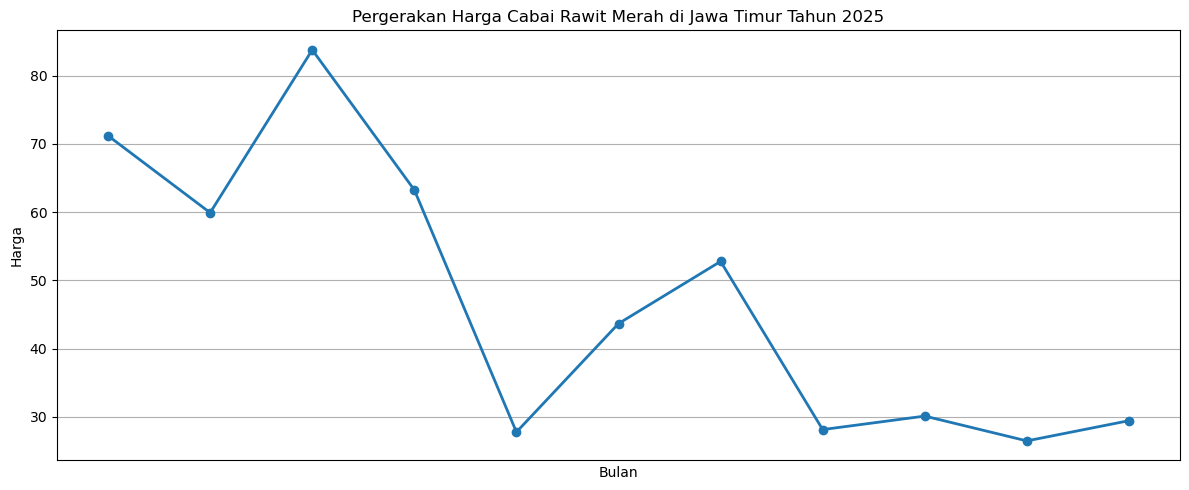

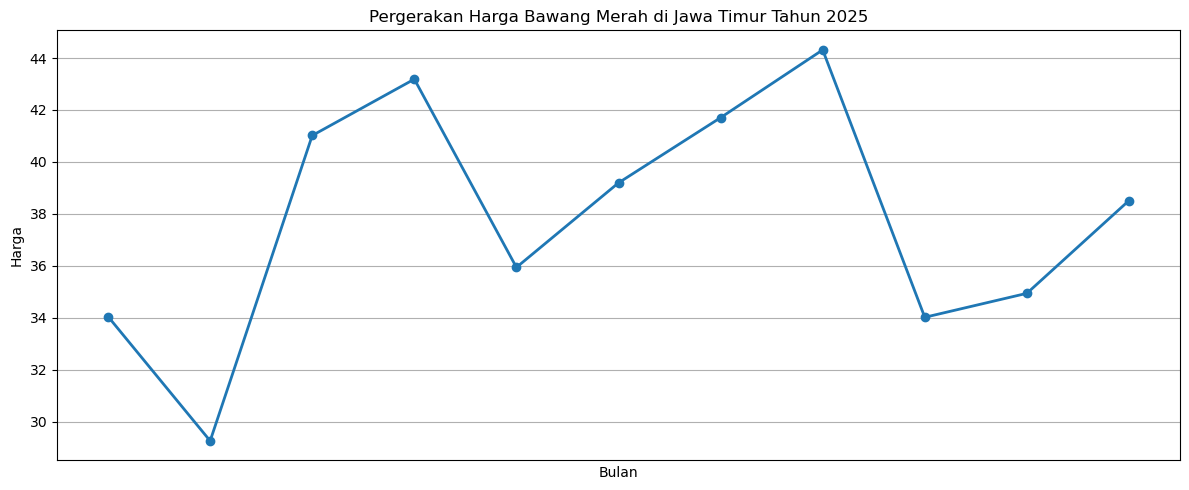

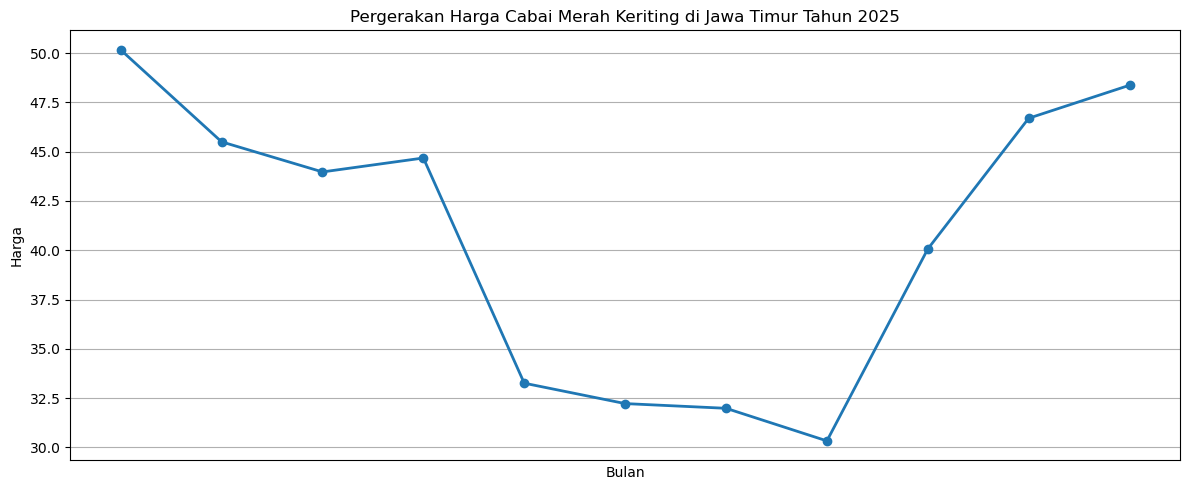

In [44]:
for komoditas in komoditas_valid:

    subset = data_aktual[
        data_aktual[KOLOM_KOMODITAS].astype(str) == komoditas
    ].copy()

    subset = subset.dropna(
        subset=["tanggal", "harga_numerik"]
    )

    subset = subset.sort_values("tanggal")

    plt.figure(figsize=(12, 5))

    plt.plot(
        subset["tanggal"],
        subset["harga_numerik"],
        marker="o",
        linewidth=2
    )

    plt.title(
        f"Pergerakan Harga {komoditas} "
        "di Jawa Timur Tahun 2025"
    )

    plt.xlabel("Bulan")
    plt.ylabel("Harga")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [45]:
ringkasan_harga = (
    data_aktual[
        data_aktual[KOLOM_KOMODITAS]
        .astype(str)
        .isin(komoditas_valid)
    ]
    .groupby(KOLOM_KOMODITAS)["harga_numerik"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
)

ringkasan_harga.columns = [
    "Jumlah Data",
    "Rata-rata",
    "Median",
    "Minimum",
    "Maksimum",
    "Standar Deviasi"
]

display(ringkasan_harga)

,Jumlah Data,Rata-rata,Median,Minimum,Maksimum,Standar Deviasi
Komoditas,,,,,,
Bawang Merah,11,37.830091,38.512,29.260,44.313,4.608902
Cabai Merah Keriting,11,40.657909,43.974,30.326,50.167,7.385835
Cabai Rawit Merah,11,46.945545,43.655,26.453,83.791,20.393649


In [46]:
for komoditas in komoditas_valid:

    subset = data_aktual[
        data_aktual[KOLOM_KOMODITAS].astype(str) == komoditas
    ].copy()

    subset = subset.dropna(
        subset=["tanggal", "harga_numerik"]
    )

    subset = subset.sort_values("tanggal")

    subset["perubahan_harga"] = (
        subset["harga_numerik"].diff()
    )

    print("\nKomoditas:", komoditas)

    display(
        subset[
            [
                KOLOM_TANGGAL,
                "harga_numerik",
                "perubahan_harga"
            ]
        ]
    )


Komoditas: Cabai Rawit Merah


,Urutan Bulan,harga_numerik,perubahan_harga
84,1,71.199,NaN
85,2,59.913,-11.286
86,3,83.791,23.878
87,4,63.250,-20.541
88,5,27.748,-35.502
89,6,43.655,15.907
90,7,52.770,9.115
91,8,28.112,-24.658
92,9,30.092,1.980
93,10,26.453,-3.639



Komoditas: Bawang Merah


,Urutan Bulan,harga_numerik,perubahan_harga
0,1,34.046,NaN
1,2,29.260,-4.786
2,3,41.017,11.757
3,4,43.186,2.169
4,5,35.940,-7.246
5,6,39.194,3.254
6,7,41.704,2.510
7,8,44.313,2.609
8,9,34.018,-10.295
9,10,34.941,0.923



Komoditas: Cabai Merah Keriting


,Urutan Bulan,harga_numerik,perubahan_harga
72,1,50.167,NaN
73,2,45.501,-4.666
74,3,43.974,-1.527
75,4,44.681,0.707
76,5,33.254,-11.427
77,6,32.219,-1.035
78,7,31.980,-0.239
79,8,30.326,-1.654
80,9,40.064,9.738
81,10,46.698,6.634


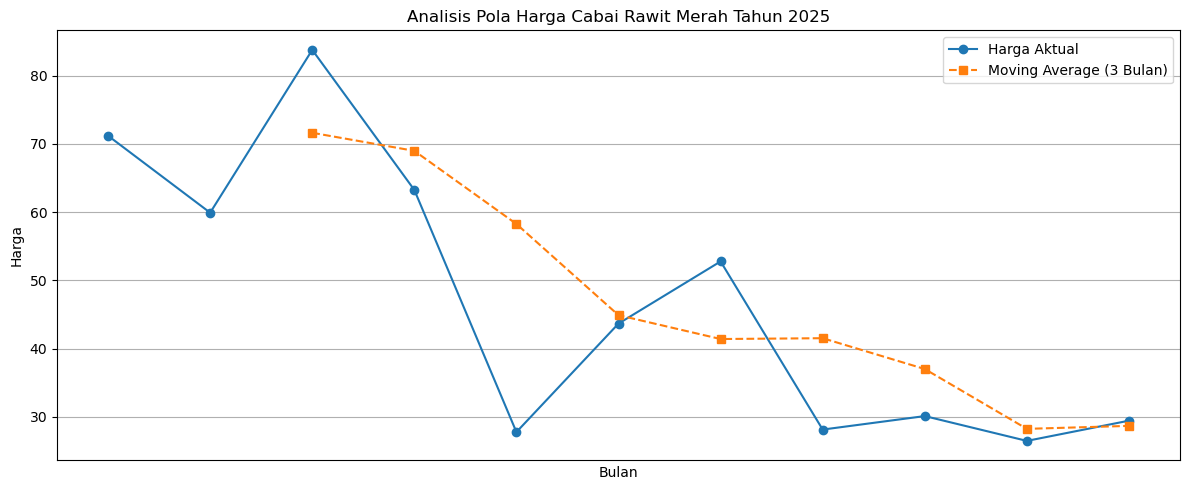

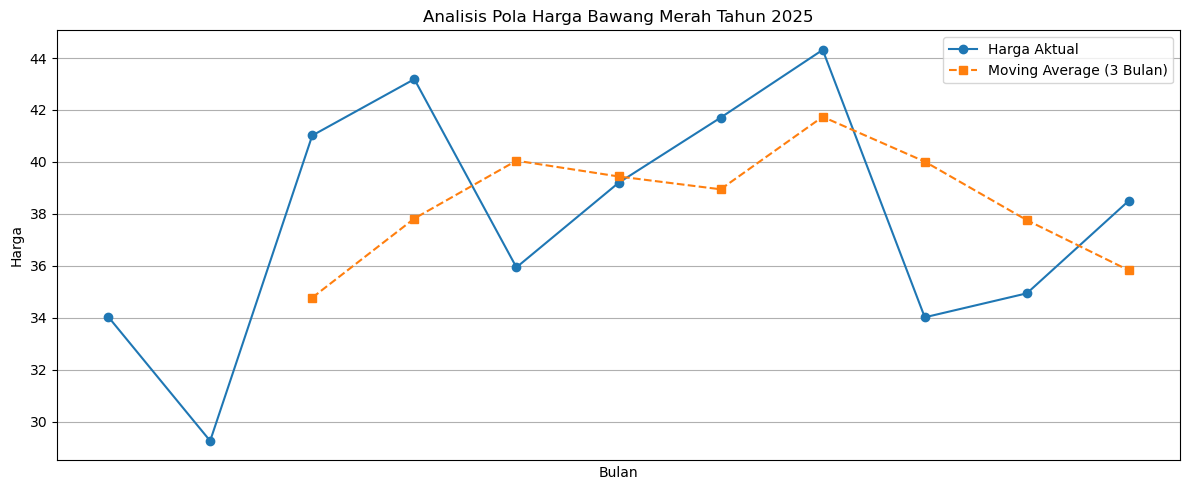

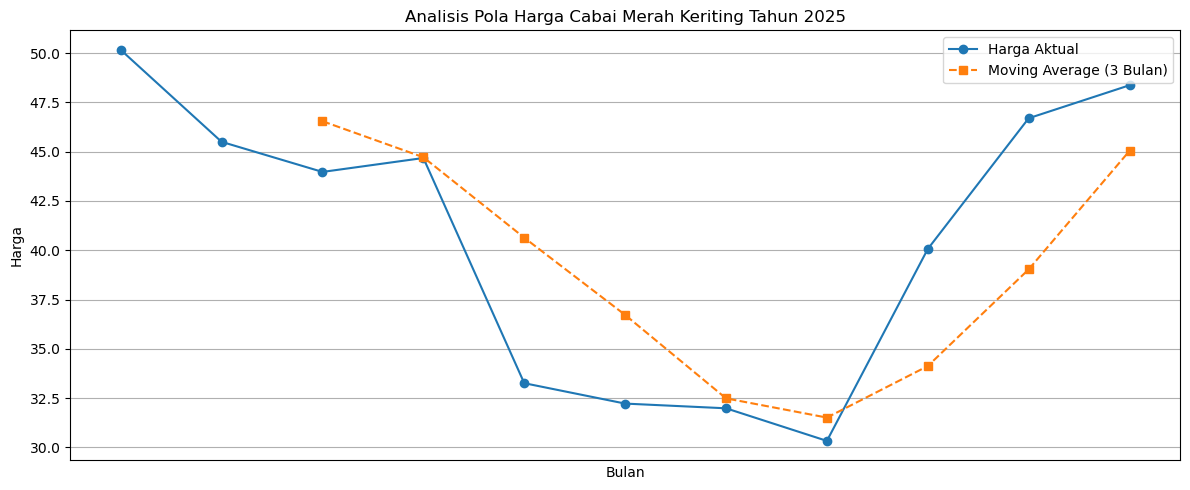

In [47]:
for komoditas in komoditas_valid:

    subset = data_aktual[
        data_aktual[KOLOM_KOMODITAS].astype(str) == komoditas
    ].copy()

    subset = subset.dropna(
        subset=["tanggal", "harga_numerik"]
    )

    subset = subset.sort_values("tanggal")

    # Menghitung rata-rata bergerak 3 periode
    subset["moving_average"] = (
        subset["harga_numerik"]
        .rolling(window=3)
        .mean()
    )

    plt.figure(figsize=(12, 5))

    plt.plot(
        subset["tanggal"],
        subset["harga_numerik"],
        marker="o",
        label="Harga Aktual"
    )

    plt.plot(
        subset["tanggal"],
        subset["moving_average"],
        linestyle="--",
        marker="s",
        label="Moving Average (3 Bulan)"
    )

    plt.title(
        f"Analisis Pola Harga {komoditas} Tahun 2025"
    )

    plt.xlabel("Bulan")
    plt.ylabel("Harga")
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [48]:
missing_komoditas = (
    harga.groupby(KOLOM_KOMODITAS)
    .apply(lambda x: x.isnull().sum().sum())
    .reset_index(name="Jumlah Missing Value")
)

display(missing_komoditas)

,Komoditas,Jumlah Missing Value
0,Bawang Merah,11
1,Bawang Putih (Bonggol),11
2,Beras Medium,11
3,Beras Premium,11
4,Beras SPHP,11
5,Cabai Merah Besar,14
6,Cabai Merah Keriting,11
7,Cabai Rawit Merah,11
8,Daging Ayam Ras,11
9,Daging Kerbau Beku (Impor),24


In [49]:
print(harga.columns.tolist())

['Kode Provinsi', 'Nama Provinsi', 'Tahun', 'Urutan Bulan', 'Bulan', 'Komoditas', 'Harga', 'Harga (Rp)', 'Status Data', 'Metode Estimasi', 'Sumber Acuan']


In [50]:
display(harga.head(10))

,Kode Provinsi,Nama Provinsi,Tahun,Urutan Bulan,Bulan,Komoditas,Harga,Harga (Rp),Status Data,Metode Estimasi,Sumber Acuan
0,35,Jawa Timur,2025,1,Januari,Bawang Merah,"Rp34,046",34046.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
1,35,Jawa Timur,2025,2,Februari,Bawang Merah,"Rp29,260",29260.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
2,35,Jawa Timur,2025,3,Maret,Bawang Merah,"Rp41,017",41017.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
3,35,Jawa Timur,2025,4,April,Bawang Merah,"Rp43,186",43186.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
4,35,Jawa Timur,2025,5,Mei,Bawang Merah,"Rp35,940",35940.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
5,35,Jawa Timur,2025,6,Juni,Bawang Merah,"Rp39,194",39194.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
6,35,Jawa Timur,2025,7,Juli,Bawang Merah,"Rp41,704",41704.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
7,35,Jawa Timur,2025,8,Agustus,Bawang Merah,"Rp44,313",44313.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
8,35,Jawa Timur,2025,9,September,Bawang Merah,"Rp34,018",34018.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
9,35,Jawa Timur,2025,10,Oktober,Bawang Merah,"Rp34,941",34941.0,AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...


In [51]:
missing_per_komoditas = (
    harga.groupby("Komoditas")["Harga"]
    .apply(lambda x: x.isna().sum())
    .reset_index(name="Missing Value Harga")
)

display(missing_per_komoditas)

,Komoditas,Missing Value Harga
0,Bawang Merah,0
1,Bawang Putih (Bonggol),0
2,Beras Medium,0
3,Beras Premium,0
4,Beras SPHP,0
5,Cabai Merah Besar,1
6,Cabai Merah Keriting,0
7,Cabai Rawit Merah,0
8,Daging Ayam Ras,0
9,Daging Kerbau Beku (Impor),5


In [52]:
# Missing value khusus kolom harga per komoditas
missing_harga = (
    harga.groupby("Komoditas")
    .agg(
        Missing_Harga=("Harga", "count"),
        Missing_Harga_Rp=("Harga (Rp)", "count"),
        Total_Baris=("Komoditas", "size")
    )
    .reset_index()
)

missing_harga["Missing Harga"] = (
    missing_harga["Total_Baris"] - missing_harga["Missing_Harga"]
)

missing_harga["Missing Harga (Rp)"] = (
    missing_harga["Total_Baris"] - missing_harga["Missing_Harga_Rp"]
)

display(missing_harga)

,Komoditas,Missing_Harga,Missing_Harga_Rp,Total_Baris,Missing Harga,Missing Harga (Rp)
0,Bawang Merah,12,12,12,0,0
1,Bawang Putih (Bonggol),12,12,12,0,0
2,Beras Medium,12,12,12,0,0
3,Beras Premium,12,12,12,0,0
4,Beras SPHP,12,12,12,0,0
5,Cabai Merah Besar,11,11,12,1,1
6,Cabai Merah Keriting,12,12,12,0,0
7,Cabai Rawit Merah,12,12,12,0,0
8,Daging Ayam Ras,12,12,12,0,0
9,Daging Kerbau Beku (Impor),7,5,12,5,7


In [53]:
print("Status Data:")
display(harga["Status Data"].value_counts(dropna=False))

print("Metode Estimasi:")
display(harga["Metode Estimasi"].value_counts(dropna=False))

Status Data:


Status Data
AKTUAL - SESUAI FILE SUMBER             271
ESTIMASI - BUKAN DATA AKTUAL BULANAN     25
TIDAK TERSEDIA DALAM FILE SUMBER          4
Name: count, dtype: int64

Metode Estimasi:


Metode Estimasi
NaN                                                                                   275
Estimasi sementara: memakai harga November 2025 (last observation carried forward)     13
Estimasi proksi: rata-rata harga harian SP2KP 19 & 23 Desember 2025                    12
Name: count, dtype: int64

**Catatan metodologis:** Visualisasi hanya memberikan indikasi awal. Untuk memastikan bahwa data benar-benar **tidak stasioner** (syarat penting sebelum pemodelan), kita lakukan uji statistik formal yaitu *Augmented Dickey-Fuller (ADF) Test*.

In [57]:
import pandas as pd
import numpy as np

# Pastikan data harga sudah terbaca (mengambil variabel 'harga' yang ada di memori)
if 'harga' in locals():
    # Pembersihan data otomatis jika belum dijalankan dari Bagian 6
    harga["Harga (Rp)"] = pd.to_numeric(harga["Harga (Rp)"], errors="coerce")
    harga["Urutan Bulan"] = pd.to_numeric(harga["Urutan Bulan"], errors="coerce")
    harga["Tahun"] = pd.to_numeric(harga["Tahun"], errors="coerce")

    harga["Tanggal"] = pd.to_datetime(
        dict(year=harga["Tahun"], month=harga["Urutan Bulan"], day=1),
        errors="coerce"
    )

    mask_aktual = harga["Status Data"].astype(str).str.upper().str.startswith("AKTUAL")
    harga_aktual = harga.loc[mask_aktual & harga["Harga (Rp)"].notna()].copy()
else:
    print("Variabel 'harga' belum ada. Pastikan kamu sudah menjalankan sel pembacaan file CSV di awal (Bagian 3).")

# Daftar komoditas yang dianalisis
kandidat_komoditas = [
    "Cabai Rawit Merah",
    "Bawang Merah",
    "Cabai Merah Keriting"
]

komoditas_tersedia = set(harga["Komoditas"].dropna().unique())
komoditas_plot = [k for k in kandidat_komoditas if k in komoditas_tersedia]

print(f"Komoditas yang dianalisis: {komoditas_plot}\n")

print("=== UJI STATISTIK STASIONERITAS (ADF TEST) ===")
print("Hipotesis:")
print("  - H0: Data Tidak Stasioner (memiliki unit root)")
print("  - H1: Data Stasioner")
print("Jika p-value > 0.05, maka data NON-STASIONER (sesuai instruksi tugas).\n")

from statsmodels.tsa.stattools import adfuller

for komoditas in komoditas_plot:
    data_k = harga_aktual[harga_aktual["Komoditas"] == komoditas].set_index("Tanggal")["Harga (Rp)"].dropna()
    
    if len(data_k) > 5:
        result = adfuller(data_k)
        adf_stat = result[0]
        p_value = result[1]
        
        status = "Non-Stasioner (Gagal Tolak H0)" if p_value > 0.05 else "Stasioner (Tolak H0)"
        
        print(f"Komoditas: {komoditas}")
        print(f"  - ADF Statistic : {adf_stat:.4f}")
        print(f"  - p-value       : {p_value:.4f}")
        print(f"  - Kesimpulan    : {status}\n")
    else:
        print(f"Komoditas: {komoditas} -> Observasi aktual kurang dari 5, uji ADF tidak bisa dijalankan.\n")

Komoditas yang dianalisis: ['Cabai Rawit Merah', 'Bawang Merah', 'Cabai Merah Keriting']

=== UJI STATISTIK STASIONERITAS (ADF TEST) ===
Hipotesis:
  - H0: Data Tidak Stasioner (memiliki unit root)
  - H1: Data Stasioner
Jika p-value > 0.05, maka data NON-STASIONER (sesuai instruksi tugas).

Komoditas: Cabai Rawit Merah
  - ADF Statistic : -2.5731
  - p-value       : 0.0987
  - Kesimpulan    : Non-Stasioner (Gagal Tolak H0)

Komoditas: Bawang Merah
  - ADF Statistic : -2.6158
  - p-value       : 0.0898
  - Kesimpulan    : Non-Stasioner (Gagal Tolak H0)

Komoditas: Cabai Merah Keriting
  - ADF Statistic : -14.2218
  - p-value       : 0.0000
  - Kesimpulan    : Stasioner (Tolak H0)



### Interpretasi Hasil Uji Stasioneritas (ADF Test)

Berdasarkan hasil pengujian *Augmented Dickey-Fuller* (ADF) pada ketiga komoditas pangan di Jawa Timur tahun 2025:

1. **Cabai Rawit Merah** ($p\text{-value} = 0.0987 > 0.05$):
   - **Keputusan:** Gagal menolak $H_0$.
   - **Kesimpulan:** Data harga Cabai Rawit Merah terbukti **non-stasioner** (memiliki *unit root* atau tren/fluktuasi yang tidak konstan di sekitar rata-rata sepanjang waktu).

2. **Bawang Merah** ($p\text{-value} = 0.0898 > 0.05$):
   - **Keputusan:** Gagal menolak $H_0$.
   - **Kesimpulan:** Data harga Bawang Merah terbukti **non-stasioner**.

3. **Cabai Merah Keriting** ($p\text{-value} = 0.0000 < 0.05$):
   - **Keputusan:** Menolak $H_0$.
   - **Kesimpulan:** Data harga Cabai Merah Keriting terbukti **stasioner** karena nilai $p\text{-value}$ berada di bawah taraf signifikansi 5% ($\alpha = 0.05$).

---

#### **Kesimpulan untuk Tugas Progres:**
Sesuai instruksi bahwa data yang digunakan **harus yang tidak stasioner**, berfokus mengangkat komoditas **Cabai Rawit Merah** dan **Bawang Merah** sebagai contoh utama data *non-stasioner* untuk dilanjutkan ke tahap pemodelan deret waktu (seperti proses *differencing* pada model ARIMA).

## Visualisasi Khusus Komoditas dengan Data Non-Stasioner

Berdasarkan hasil uji ADF sebelumnya, komoditas **Cabai Rawit Merah** dan **Bawang Merah** menunjukkan karakteristik data yang **tidak stasioner** ($p\text{-value} > 0.05$). Grafik berikut memvisualisasikan secara spesifik pergerakan harga kedua komoditas tersebut untuk memperjelas pola ketidakstasionerannya (adanya fluktuasi tajam/tren tingkat harga sepanjang periode 2025).

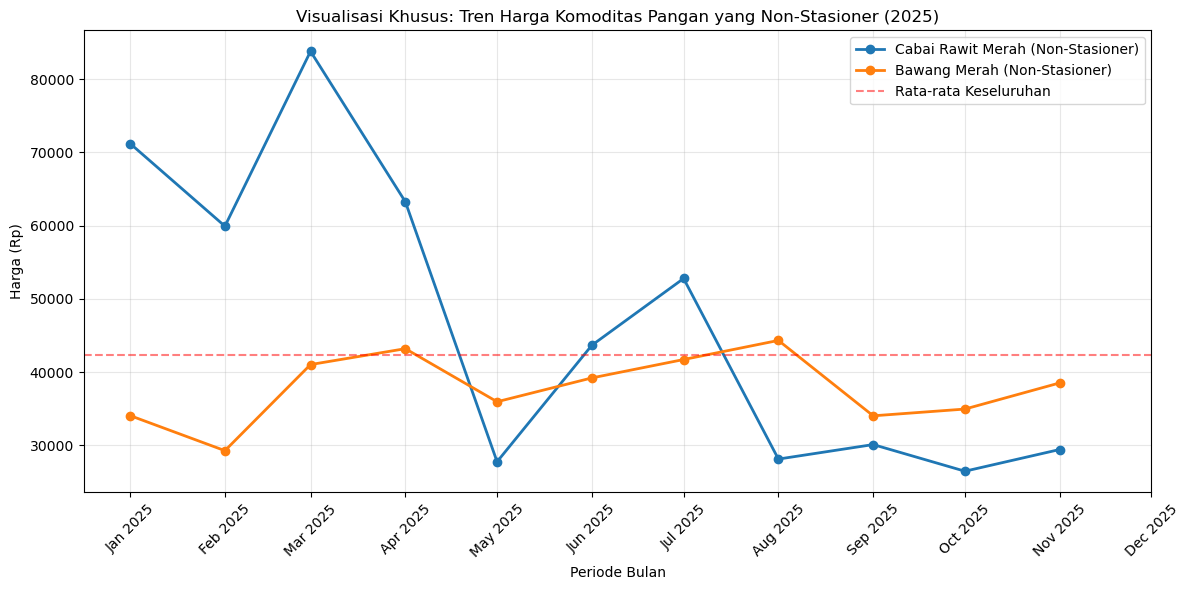

In [58]:
# Memfilter hanya komoditas yang terbukti non-stasioner berdasarkan uji ADF
komoditas_non_stasioner = ["Cabai Rawit Merah", "Bawang Merah"]
periode_lengkap = pd.date_range("2025-01-01", "2025-12-01", freq="MS")

plt.figure(figsize=(12, 6))

for komoditas in komoditas_non_stasioner:
    data_k = harga_aktual[harga_aktual["Komoditas"] == komoditas].copy()
    data_k = data_k.set_index("Tanggal")["Harga (Rp)"].reindex(periode_lengkap)
    
    plt.plot(data_k.index, data_k.values, marker="o", linewidth=2, label=f"{komoditas} (Non-Stasioner)")

plt.title("Visualisasi Khusus: Tren Harga Komoditas Pangan yang Non-Stasioner (2025)")
plt.xlabel("Periode Bulan")
plt.ylabel("Harga (Rp)")
plt.xticks(periode_lengkap, [d.strftime("%b %Y") for d in periode_lengkap], rotation=45)
plt.axhline(y=harga_aktual[harga_aktual["Komoditas"].isin(komoditas_non_stasioner)]["Harga (Rp)"].mean(), 
            color="red", linestyle="--", alpha=0.5, label="Rata-rata Keseluruhan")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

1. Berdasarkan Nilai Statistik Uji ADF (p-value)Cabai Rawit Merah: Memiliki nilai $p\text{-value} = 0,0987$ (di mana $0,0987 > 0,05$). Keputusannya adalah gagal menolak $H_0$, yang berarti data mengandung unit root (tidak stasioner).   Bawang Merah: Memiliki nilai $p\text{-value} = 0,0898$ (di mana $0,0898 > 0,05$). Keputusannya juga gagal menolak $H_0$, sehingga terbukti non-stasioner.   Sebagai perbandingan: Cabai Merah Keriting memiliki $p\text{-value} = 0,0000$ (< 0,05) yang artinya stasioner karena berada di bawah taraf signifikansi 5%.

2. Berdasarkan Karakteristik Visual Grafik Jika dilihat dari grafik "Visualisasi Khusus: Tren Harga Komoditas Pangan yang Non-Stasioner (2025)", ketidakstasioneran data ini terlihat jelas dari:Fluktuasi yang Tidak Konstan di Sekitar Rata-rata: Rata-rata keseluruhan (garis putus-putus merah) menunjukkan garis horizontal yang konstan. Namun, nilai data aktual untuk Cabai Rawit Merah dan Bawang Merah naik-turun secara tajam dan tidak stabil di sekitar nilai rata-rata tersebut.   Adanya Tren dan Variasi Varian Seiring Waktu: Khususnya pada Cabai Rawit Merah (garis biru), terlihat adanya lonjakan harga yang sangat ekstrem pada bulan Maret 2025 (mencapai di atas Rp80.000) lalu turun drastis, yang menunjukkan bahwa rata-rata (mean) dan ragam (variance) data tidak konstan seiring berjalannya waktu—syarat utama data harus stasioner.

Kesimpulan:
Bagian yang membuat data ini tidak stasioner adalah nilai $p\text{-value}$ yang berada di atas taraf signifikansi 5% ($> 0,05$) serta pergerakan data (tren dan varians) yang tidak stabil atau berfluktuasi secara ekstrem di sekitar nilai rata-rata dari waktu ke waktu. Oleh karena itu, data ini memerlukan penanganan lanjutan seperti differencing jika ingin digunakan dalam pemodelan ARIMA.